Full rebuild matches original: True


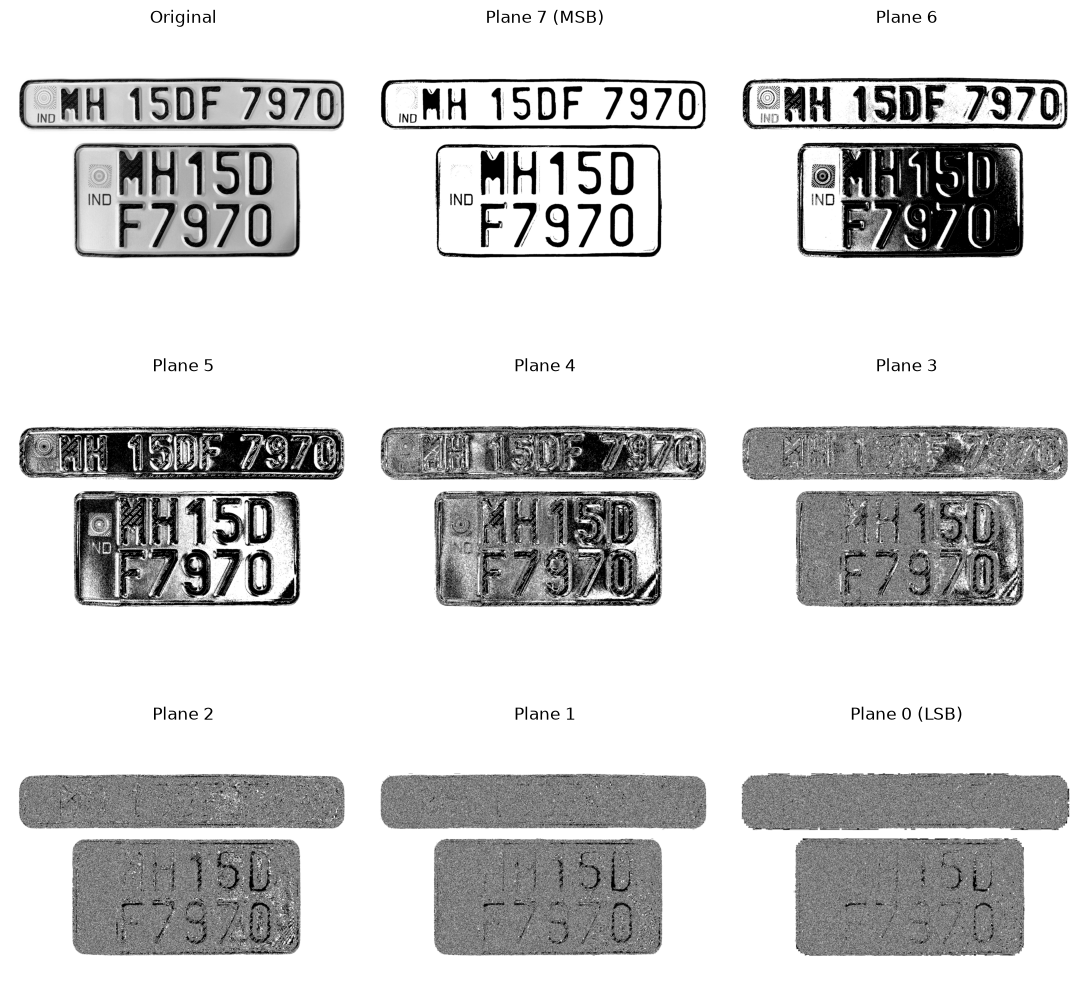

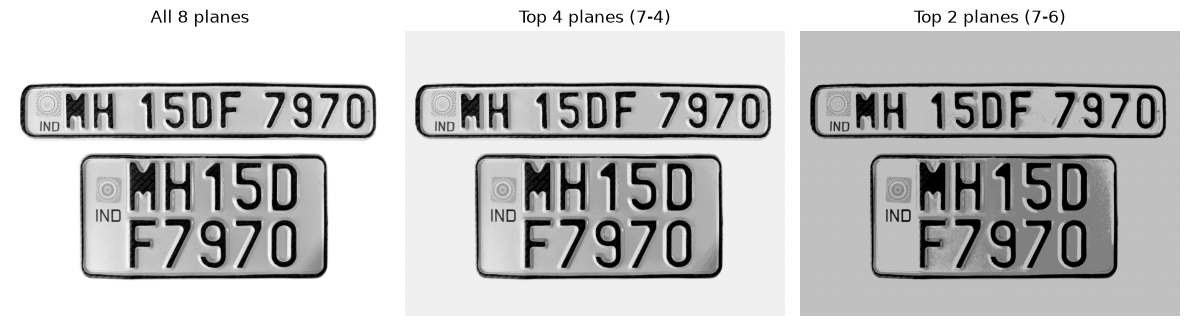

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("./images/licence plate.png", 0)
if img is None:
    raise SystemExit("Image not found, check path")

# Extract all 8 planes
planes = [(img >> k) & 1 for k in range(8)]

# Rebuild from all planes (proof that nothing was lost)
rebuilt = sum(planes[k].astype(np.uint16) << k for k in range(8)).astype(np.uint8)
print("Full rebuild matches original:", np.array_equal(rebuilt, img))

# Rebuild from only the top planes
top4 = sum(planes[k].astype(np.uint16) << k for k in range(4, 8)).astype(np.uint8)
top2 = sum(planes[k].astype(np.uint16) << k for k in range(6, 8)).astype(np.uint8)


fig, ax = plt.subplots(3, 3, figsize=(11, 11))
ax = ax.ravel()
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original")
for i, k in enumerate(range(7, -1, -1)):
    ax[i + 1].imshow(planes[k], cmap="gray", vmin=0, vmax=1)
    ax[i + 1].set_title(f"Plane {k}" + (" (MSB)" if k == 7 else " (LSB)" if k == 0 else ""))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# Figure 2: rebuild from fewer planes
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title("All 8 planes"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(top4, cmap="gray", vmin=0, vmax=255); plt.title("Top 4 planes (7-4)"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(top2, cmap="gray", vmin=0, vmax=255); plt.title("Top 2 planes (7-6)"); plt.axis("off")
plt.tight_layout()
plt.show()